# 19. Complete Computer Vision Project: CIFAR-10 Image Classification


## 1. Problem definition

**Task:** given a 32 × 32 color image, predict one of ten object classes (such as airplane, bird, or truck). This is a multi-class image-classification problem: one image gets one label.

**Success criteria:** beat the majority-class baseline on a validation set, compare validation accuracy before using the test set, report macro precision/recall/F1 and a confusion matrix, inspect mistakes, and save a model that can predict one new image.

**Decision and limitation:** CIFAR-10 is already available locally and keeps the project reproducible without a download. Its tiny benchmark images are not representative of every real camera or business setting; this project is educational, not a production guarantee.

**Example:** a picture of a car is one input and `automobile` is its target. Confusing an automobile with a truck is more informative than reporting accuracy alone.

## 2. Dataset collection and selection

We use CIFAR-10 from `data/cifar-10-batches-py`. `download=False` is intentional: the project should use the data already in this workspace and clearly report if it is missing. The official training split is divided into a small training subset and a validation subset; the official test split is held until final evaluation.

**Interpretation:** the checks below should show 50,000 training images, 10,000 test images, and ten class names. If the local files are missing, fix the data location rather than silently downloading another copy.

In [28]:
from pathlib import Path
import copy
import io
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from torchvision import datasets, models, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
DATA_ROOT = Path("data")
CHECKPOINT = Path("artifacts/resnet18_cifar10_finetuned.pth")
BATCH_SIZE = 64
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if not (DATA_ROOT / "cifar-10-batches-py").is_dir():
    raise FileNotFoundError("CIFAR-10 files are missing. Expected data/cifar-10-batches-py/.")
raw_train = datasets.CIFAR10(DATA_ROOT, train=True, download=False)
raw_test = datasets.CIFAR10(DATA_ROOT, train=False, download=False)
class_names = raw_train.classes
print("Device:", device)
print("Train/test sizes:", len(raw_train), len(raw_test))
print("Classes:", class_names)

Device: cpu
Train/test sizes: 50000 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Dataset validation

Before modeling, verify image dimensions, color channels, labels, and class counts. CIFAR-10 stores images as RGB and labels as integers from 0 to 9. We also confirm that every label maps to a known class.

**Example:** a valid batch has shape `(batch, 3, 32, 32)` after tensor conversion. The first dimension is the number of images; `3` is RGB.

**Interpretation:** equal class counts in this benchmark mean a majority-class baseline should be close to 10%. A very different result would suggest a loading or label problem.

In [29]:
train_targets = np.asarray(raw_train.targets)
test_targets = np.asarray(raw_test.targets)
image, label = raw_train[0]
assert image.mode == "RGB" and image.size == (32, 32)
assert set(np.unique(train_targets)).issubset(set(range(len(class_names))))
print("One image:", image.mode, image.size, "label:", label, "->", class_names[label])
print("Training examples per class:", dict(zip(class_names, np.bincount(train_targets, minlength=10))))
print("Test examples per class:", dict(zip(class_names, np.bincount(test_targets, minlength=10))))
print("Validation passed: RGB 32x32 images and known labels.")

One image: RGB (32, 32) label: 6 -> frog
Training examples per class: {'airplane': np.int64(5000), 'automobile': np.int64(5000), 'bird': np.int64(5000), 'cat': np.int64(5000), 'deer': np.int64(5000), 'dog': np.int64(5000), 'frog': np.int64(5000), 'horse': np.int64(5000), 'ship': np.int64(5000), 'truck': np.int64(5000)}
Test examples per class: {'airplane': np.int64(1000), 'automobile': np.int64(1000), 'bird': np.int64(1000), 'cat': np.int64(1000), 'deer': np.int64(1000), 'dog': np.int64(1000), 'frog': np.int64(1000), 'horse': np.int64(1000), 'ship': np.int64(1000), 'truck': np.int64(1000)}
Validation passed: RGB 32x32 images and known labels.


## 4. Exploratory data analysis (EDA)

EDA means looking at the data before choosing a model. The chart shows class balance and the image grid shows what examples look like. CIFAR-10 images are small, so fine details may be ambiguous even for a person.

**Interpretation:** check that class counts are balanced and that displayed pictures match their labels. These checks help catch obvious data/label issues before training.

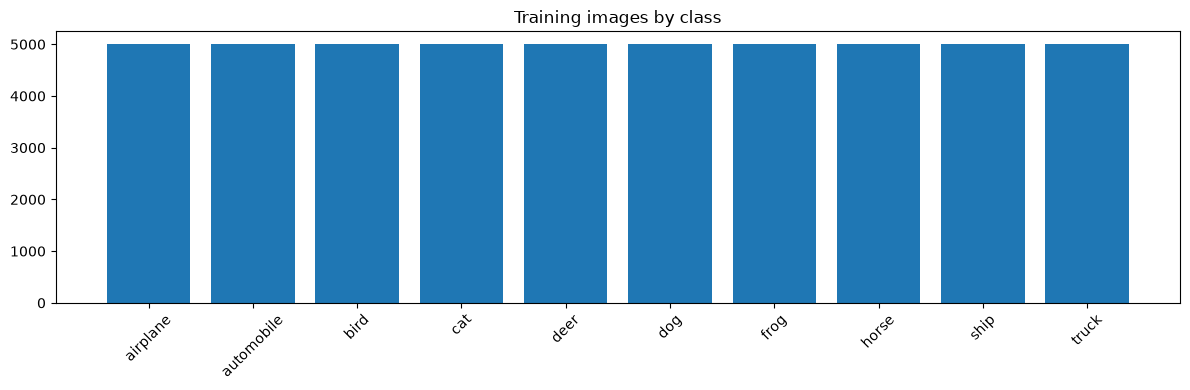

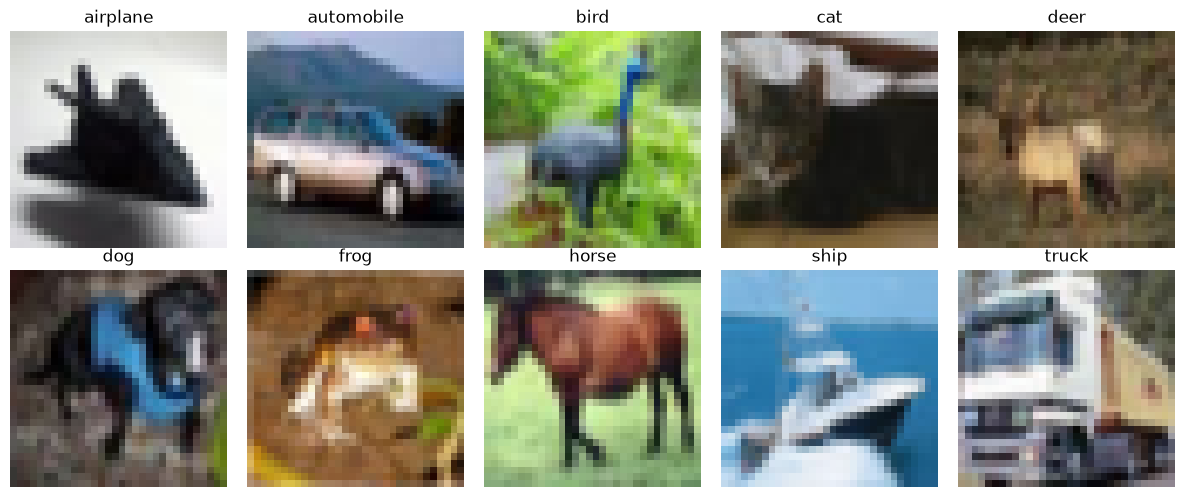

In [30]:
counts = np.bincount(train_targets, minlength=len(class_names))
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(class_names, counts)
ax.tick_params(axis="x", rotation=45)
ax.set_title("Training images by class")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    sample_id = int(np.where(train_targets == class_id)[0][0])
    sample, _ = raw_train[sample_id]
    ax.imshow(sample)
    ax.set_title(class_names[class_id])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Preprocessing

Neural networks use numeric tensors rather than PIL images. `ToTensor()` converts RGB pixels to floating-point values from 0 to 1; normalization recenters each channel using CIFAR-10's approximate mean and standard deviation. These values are also used consistently for training and evaluation.

**Example:** an image changes from width-height-channel `(32, 32, 3)` to channel-height-width `(3, 32, 32)`.

**Interpretation:** confirm that the transformed tensor has three channels and finite values. Normalization does not change the label or image geometry.

In [31]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
plain_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
example_tensor = plain_transform(image)
print("Tensor shape:", tuple(example_tensor.shape))
print("Finite values:", bool(torch.isfinite(example_tensor).all()))

Tensor shape: (3, 32, 32)
Finite values: True


## 6. Data augmentation

Augmentation creates varied training views without collecting extra images. We apply a small padded crop and a horizontal flip **only to training images**; validation and test images remain unchanged. This helps a model tolerate small shifts and left-right changes.

**Example:** the same training image can be randomly shifted or mirrored on different visits. Do not use transformations that change the meaning of a label.

**Interpretation:** the shown images are examples of possible variants, not new independent observations. Augmentation may help generalization but does not guarantee better results.

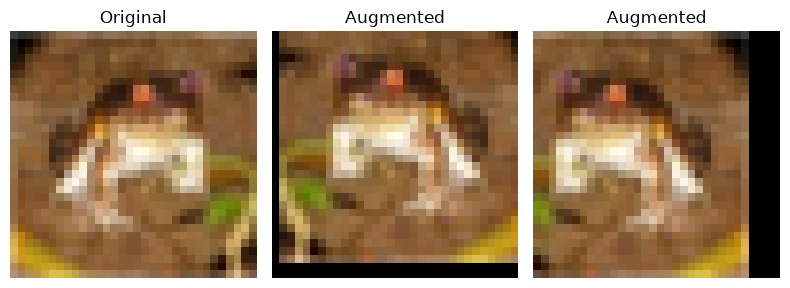

In [32]:
augmented_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=1.0),
])
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
axes[0].imshow(image); axes[0].set_title("Original")
for ax in axes:
    ax.axis("off")
for ax in axes[1:]:
    ax.imshow(augmented_transform(image))
    ax.set_title("Augmented")
plt.tight_layout(); plt.show()

## 7. Reproducible train, validation, and test subsets

We sample the same number of images from each class: 100 per class for training, 30 per class for validation, and 50 per class from the official test set for the final report. The test subset is not used to tune model settings. This keeps CPU training short and comparisons fair, but scores are less precise than using every image. To avoid a memory error, each transformed dataset below is a lightweight view over the two arrays already loaded above; it does not reopen and duplicate all CIFAR images for each transform. Because the earlier failed attempt may have left duplicate datasets in kernel memory, restart the kernel and run the notebook from the top before retrying.

**Interpretation:** expect 1,000 train, 300 validation, and 500 test images. Fixing the seed makes the chosen examples repeatable.

In [33]:
rng = np.random.default_rng(SEED)
train_ids, val_ids, test_ids = [], [], []
for class_id in range(len(class_names)):
    train_class = rng.permutation(np.where(train_targets == class_id)[0])
    train_ids.extend(train_class[:100])
    val_ids.extend(train_class[100:130])
    test_class = rng.permutation(np.where(test_targets == class_id)[0])
    test_ids.extend(test_class[:50])
print("Subset sizes:", len(train_ids), len(val_ids), len(test_ids))
class CIFARTransformView(Dataset):
    """Apply a transform to selected images without loading another CIFAR-10 copy."""
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        source_index = self.indices[index]
        image = Image.fromarray(self.base_dataset.data[source_index])
        label = int(self.base_dataset.targets[source_index])
        return self.transform(image), label

transfer_train_transform = transforms.Compose([
    transforms.Resize((96, 96)), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize((0.485, 0.456, 0.406),
                                                   (0.229, 0.224, 0.225)),
])
train_dataset = CIFARTransformView(raw_train, train_ids, train_transform)
val_dataset = CIFARTransformView(raw_train, val_ids, plain_transform)
test_dataset = CIFARTransformView(raw_test, test_ids, plain_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
transfer_eval_transform = transforms.Compose([
    transforms.Resize((96, 96)), transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
transfer_val_dataset = CIFARTransformView(raw_train, val_ids, transfer_eval_transform)
transfer_test_dataset = CIFARTransformView(raw_test, test_ids, transfer_eval_transform)
transfer_train_dataset = CIFARTransformView(raw_train, train_ids, transfer_train_transform)
transfer_train_loader = DataLoader(transfer_train_dataset, batch_size=32, shuffle=True)
transfer_val_loader = DataLoader(transfer_val_dataset, batch_size=32, shuffle=False)
transfer_test_loader = DataLoader(transfer_test_dataset, batch_size=32, shuffle=False)
print("Train and test image arrays are shared by all preprocessing views.")

Subset sizes: 1000 300 500
Train and test image arrays are shared by all preprocessing views.


## 8. Baseline model

A baseline is a simple score to beat. Here we predict the most common training class for every image. Because classes are balanced, this should be around 10% accuracy; it confirms that a learned model is doing more than repeatedly guessing one label.

**Interpretation:** later validation accuracy should improve clearly over the baseline. If not, check the labels, learning loop, and input preprocessing.

In [34]:
majority_class = int(np.bincount(train_targets[train_ids], minlength=10).argmax())
y_val = train_targets[val_ids]
baseline_predictions = np.full(len(val_ids), majority_class)
baseline_accuracy = accuracy_score(y_val, baseline_predictions)
print("Baseline class:", class_names[majority_class])
print(f"Validation baseline accuracy: {baseline_accuracy:.3f}")

Baseline class: airplane
Validation baseline accuracy: 0.100


## 9. CNN from scratch

A convolutional neural network (CNN) learns local image patterns. Early filters can respond to edges or colors; later layers combine them into more useful shapes. This small model has two convolution blocks and a classifier, which keeps the example readable and CPU-friendly.

**Example:** the model receives a batch shaped `(64, 3, 32, 32)` and returns ten scores per image. The largest score is the predicted class.

**Interpretation:** the loss should generally fall during training. Validation accuracy measures performance on examples the optimizer did not train on.

In [35]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 8 * 8, 128),
                                        nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

def train_model(model, loader, epochs=1, learning_rate=0.001):
    model = model.to(device)
    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=learning_rate)
    loss_fn = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(images), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)
        print(f"Epoch {epoch + 1}/{epochs} - train loss: {total_loss / len(loader.dataset):.4f}")
    return model

def predict(model, loader):
    model.eval()
    all_predictions, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.asarray(all_predictions), np.asarray(all_labels)

cnn_model = train_model(SmallCNN(), train_loader, epochs=2, learning_rate=0.001)
cnn_val_predictions, y_val = predict(cnn_model, val_loader)
cnn_val_accuracy = accuracy_score(y_val, cnn_val_predictions)
print(f"CNN validation accuracy: {cnn_val_accuracy:.3f} (baseline: {baseline_accuracy:.3f})")

Epoch 1/2 - train loss: 2.2898
Epoch 2/2 - train loss: 2.0996
CNN validation accuracy: 0.263 (baseline: 0.100)


## 10. Transfer learning

Transfer learning starts with visual features learned earlier rather than random weights. This folder includes a ResNet-18 checkpoint produced by the earlier transfer-learning lesson. We load its compatible feature weights, replace its 10-class head with a fresh classifier, freeze the backbone, and train the new head briefly.

**Important limitation:** the saved checkpoint was already fine-tuned on CIFAR-10, so some images may overlap with our validation or test sets. This is an instructional warm-start, not an unbiased transfer-learning benchmark. The scratch CNN is the cleaner comparison.

**Interpretation:** compare validation accuracy and runtime, not just the model name. The larger ResNet still computes every frozen layer during training and inference.

In [41]:
if not CHECKPOINT.is_file():
    raise FileNotFoundError(f"Transfer checkpoint missing: {CHECKPOINT}")

transfer_model = models.resnet18(weights=None)

transfer_model.fc = nn.Linear(
    transfer_model.fc.in_features,
    len(class_names)
)

checkpoint_state = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

transfer_model.load_state_dict(checkpoint_state, strict=True)

for parameter in transfer_model.parameters():
    parameter.requires_grad = False

transfer_model = transfer_model.to(device).eval()

print("Transfer learning model loaded successfully!")

Transfer learning model loaded successfully!


## 11. Small hyperparameter experiment

A learning rate controls the size of each optimizer update. We compare two values while keeping the training subset, architecture, batch size, and one-epoch budget fixed. We use validation accuracy to make a choice; the test set remains untouched.

**Example:** a rate that is too high may jump past a useful solution; one that is too low may learn slowly.

**Interpretation:** select the learning rate with the better measured validation accuracy, but treat tiny score differences cautiously because this experiment is small and random.

In [42]:
lr_results = {}
for learning_rate in (0.0003, 0.003):
    print(f"\nLearning rate: {learning_rate}")
    candidate = train_model(SmallCNN(), train_loader, epochs=1, learning_rate=learning_rate)
    candidate_predictions, candidate_labels = predict(candidate, val_loader)
    lr_results[learning_rate] = {
        "model": candidate,
        "accuracy": accuracy_score(candidate_labels, candidate_predictions),
    }
    print(f"Validation accuracy: {lr_results[learning_rate]['accuracy']:.3f}")
best_lr = max(lr_results, key=lambda rate: lr_results[rate]["accuracy"])
print("Best measured learning rate:", best_lr)


Learning rate: 0.0003
Epoch 1/1 - train loss: 2.2629
Validation accuracy: 0.270

Learning rate: 0.003
Epoch 1/1 - train loss: 2.2403
Validation accuracy: 0.210
Best measured learning rate: 0.0003


## 12. Choose a final candidate using validation data

We choose between the scratch CNN and the two learning-rate experiments using validation accuracy only. The transferred checkpoint has a known data-overlap limitation, so we report it separately instead of letting its potentially optimistic score decide the final model.

**Interpretation:** the printed result states which scratch model had the best validation score. If another model is close, consider its simplicity and runtime too.

In [43]:
scratch_candidates = {0.001: {"model": cnn_model, "accuracy": cnn_val_accuracy}}
scratch_candidates.update(lr_results)
selected_lr = max(scratch_candidates, key=lambda rate: scratch_candidates[rate]["accuracy"])
print(f"Selected scratch-CNN learning rate: {selected_lr}")
print(f"Selected validation accuracy: {scratch_candidates[selected_lr]['accuracy']:.3f}")


Selected scratch-CNN learning rate: 0.0003
Selected validation accuracy: 0.270


## 13. Final evaluation

Now we evaluate the selected scratch model and the transfer model on the same held-out test subset. Accuracy is the fraction correct. Macro precision, recall, and F1 average the ten classes equally, so each class matters even when class frequencies differ.

**Decision:** only use test metrics now, after the validation-based choice. Test scores estimate performance on this sampled split; the transfer score remains potentially optimistic because its original checkpoint may have seen these images.

**Interpretation:** compare all four metrics. A high accuracy can still hide poor performance on a particular class, which the confusion matrix will reveal.

In [44]:
final_model = SmallCNN()
final_model.load_state_dict(scratch_candidates[selected_lr]["model"].cpu().state_dict())
final_model = final_model.to(device).eval()
cnn_test_predictions, y_test = predict(final_model, test_loader)
transfer_test_predictions, transfer_y_test = predict(transfer_model, transfer_test_loader)
print("Scratch CNN test report:")
print(classification_report(y_test, cnn_test_predictions, target_names=class_names, zero_division=0))
print("Transfer model test report (checkpoint overlap caveat applies):")
print(classification_report(transfer_y_test, transfer_test_predictions, target_names=class_names, zero_division=0))
print("Scratch test accuracy:", f"{accuracy_score(y_test, cnn_test_predictions):.3f}")
print("Transfer test accuracy:", f"{accuracy_score(transfer_y_test, transfer_test_predictions):.3f}")

Scratch CNN test report:
              precision    recall  f1-score   support

    airplane       0.34      0.66      0.45        50
  automobile       0.20      0.20      0.20        50
        bird       0.00      0.00      0.00        50
         cat       0.50      0.02      0.04        50
        deer       0.00      0.00      0.00        50
         dog       0.24      0.24      0.24        50
        frog       0.24      0.56      0.34        50
       horse       0.21      0.16      0.18        50
        ship       0.43      0.42      0.42        50
       truck       0.28      0.58      0.38        50

    accuracy                           0.28       500
   macro avg       0.25      0.28      0.23       500
weighted avg       0.25      0.28      0.23       500

Transfer model test report (checkpoint overlap caveat applies):
              precision    recall  f1-score   support

    airplane       0.84      0.94      0.89        50
  automobile       0.96      0.86      0.91

## 14. Error analysis

A confusion matrix counts true classes by predicted classes. Off-diagonal cells show which labels the model mixes up. We also display a few incorrect examples to look for patterns such as small objects, cluttered backgrounds, or visually similar classes.

**Interpretation:** look for repeated confusions rather than judging one mistake. These are examples of the model's limitations, not necessarily mislabeled data.

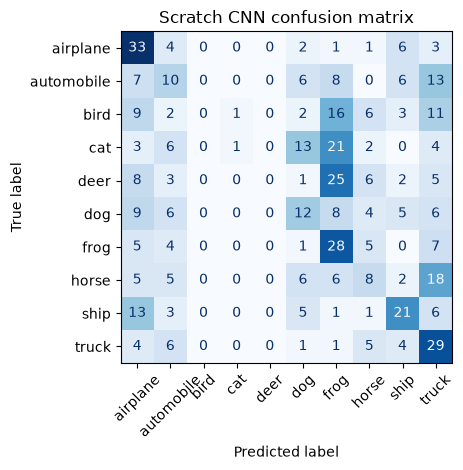

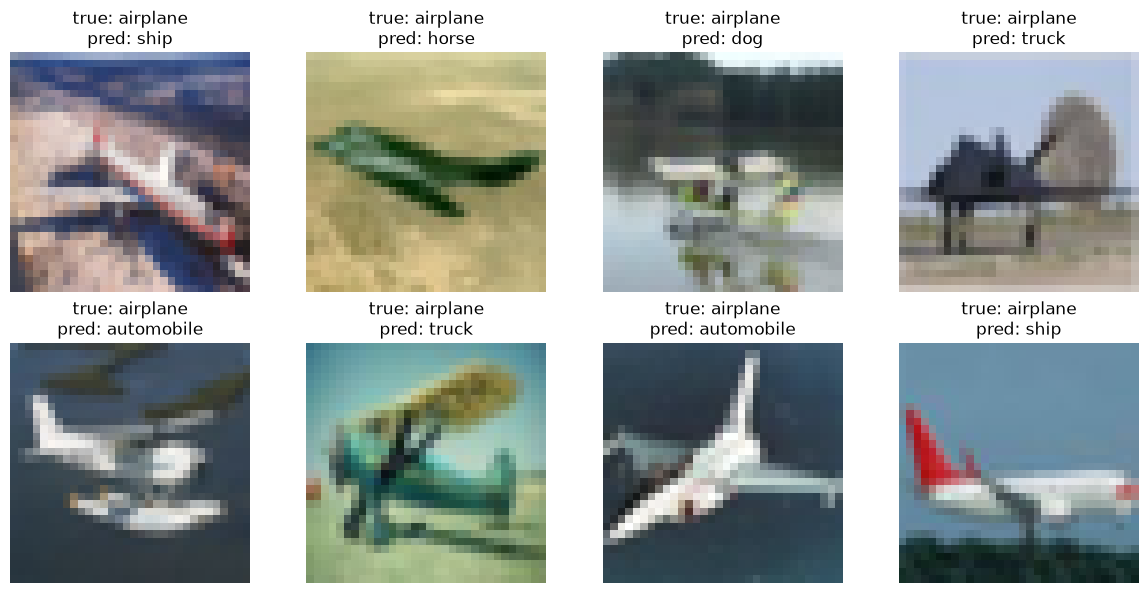

Displayed 8 incorrect test examples.


In [45]:
cm = confusion_matrix(y_test, cnn_test_predictions, labels=range(len(class_names)))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Scratch CNN confusion matrix")
plt.tight_layout(); plt.show()

wrong_positions = np.where(cnn_test_predictions != y_test)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, position in zip(axes.flat, wrong_positions):
    image_id = test_ids[position]
    raw_image, _ = raw_test[image_id]
    ax.imshow(raw_image)
    ax.set_title(f"true: {class_names[y_test[position]]}\npred: {class_names[cnn_test_predictions[position]]}")
    ax.axis("off")
plt.tight_layout(); plt.show()
print("Displayed", len(wrong_positions), "incorrect test examples.")

## 15. Explainability with input saliency

A saliency map shows which input pixels most affect the score for the model's predicted class. We use the absolute image gradient as a simple explanation technique. Bright pixels have a stronger local influence on that score.

**Caveat:** saliency is a visualization of model sensitivity, not proof of reasoning or causality. It can be noisy and should be interpreted alongside the original image and known failure cases.

**Interpretation:** check whether the highlighted region overlaps the object. If the background dominates, the model may have learned a shortcut.

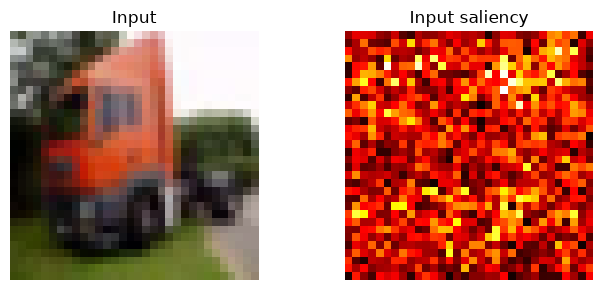

True: truck | Predicted: truck


In [46]:
saliency_image, saliency_label = test_dataset[test_ids[0]]
input_batch = saliency_image.unsqueeze(0).to(device).requires_grad_(True)
final_model.zero_grad()
saliency_scores = final_model(input_batch)
predicted_class = int(saliency_scores.argmax(dim=1).item())
saliency_scores[0, predicted_class].backward()
saliency_map = input_batch.grad.detach().abs().max(dim=1)[0][0].cpu().numpy()
display_image = saliency_image.permute(1, 2, 0).numpy() * np.asarray(CIFAR_STD) + np.asarray(CIFAR_MEAN)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(np.clip(display_image, 0, 1)); axes[0].set_title("Input")
axes[1].imshow(saliency_map, cmap="hot"); axes[1].set_title("Input saliency")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("True:", class_names[saliency_label], "| Predicted:", class_names[predicted_class])

## 16. Optimization for inference

We measure CPU inference time and compare the model's serialized size before and after dynamic INT8 quantization of linear layers. Quantization stores some weights with fewer bits; it may reduce size, but speed and accuracy effects depend on hardware and model layers. If quantization is unsupported, the cell reports the runtime error; the saved FP32 model remains unchanged.

**Interpretation:** use the measured size and latency on your own computer. A smaller checkpoint is not automatically a more accurate or faster model.

In [47]:
def serialized_size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.cpu().state_dict(), buffer)
    return buffer.tell() / (1024 ** 2)

def cpu_latency_ms(model, sample, repeats=30):
    model = model.cpu().eval()
    sample = sample.cpu()
    with torch.inference_mode():
        for _ in range(5): model(sample)
        start = time.perf_counter()
        for _ in range(repeats): model(sample)
    return (time.perf_counter() - start) * 1000 / repeats

cpu_model = copy.deepcopy(final_model).cpu().eval()
sample_batch = next(iter(test_loader))[0][:1]
fp32_size = serialized_size_mb(cpu_model)
fp32_latency = cpu_latency_ms(cpu_model, sample_batch)
quantized_model = torch.ao.quantization.quantize_dynamic(
    copy.deepcopy(cpu_model), {nn.Linear}, dtype=torch.qint8
)
quantized_size = serialized_size_mb(quantized_model)
quantized_latency = cpu_latency_ms(quantized_model, sample_batch)
print(f"FP32: {fp32_size:.2f} MB, {fp32_latency:.2f} ms/image")
print(f"Dynamic INT8: {quantized_size:.2f} MB, {quantized_latency:.2f} ms/image")
with torch.inference_mode():
    quantized_accuracy = accuracy_score(y_test, np.concatenate([
        quantized_model(images.cpu()).argmax(dim=1).numpy() for images, _ in test_loader
    ]))
print(f"Quantized test accuracy: {quantized_accuracy:.3f} (FP32: {accuracy_score(y_test, cnn_test_predictions):.3f})")

C:\Users\hemak\AppData\Local\Temp\ipykernel_9088\744803491.py:19: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.ao.quantization.quantize_dynamic(
C:\Users\hemak\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\ao\nn\quantized\modules\utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized 

FP32: 2.08 MB, 1.09 ms/image
Dynamic INT8: 0.58 MB, 1.13 ms/image
Quantized test accuracy: 0.284 (FP32: 0.284)


## 17. Final model and saved artifact

We retain the validation-selected scratch CNN as the final educational model. We save its learned weights, class names, and preprocessing values so inference can rebuild the architecture and interpret predictions. The checkpoint is written under `artifacts/`.

**Decision:** choose based on validation results and the checkpoint-overlap warning, not by selecting whichever test score is highest. For a real deployment, retrain and validate on data representative of the target cameras and users.

In [48]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FINAL_PATH = ARTIFACT_DIR / "19_cifar10_final.pth"
torch.save({
    "model_state_dict": final_model.cpu().state_dict(),
    "class_names": class_names,
    "mean": CIFAR_MEAN,
    "std": CIFAR_STD,
    "selected_learning_rate": selected_lr,
}, FINAL_PATH)
print("Saved:", FINAL_PATH.resolve())
print("File size (MB):", round(FINAL_PATH.stat().st_size / (1024 ** 2), 3))

Saved: C:\Users\hemak\Sprint 10 - Advanced Deep Learning, CNNs, Transfer Learning, and Computer Vision\artifacts\19_cifar10_final.pth
File size (MB): 2.083


## 18. Inference on one image

Inference means using a saved model to predict an image that is not part of a training step. We reload the checkpoint, apply the same normalization, and convert the model scores to probabilities with softmax.

**Example:** the output might say `cat (0.42)`. This is the model's confidence distribution, not a guarantee that its guess is correct.

**Interpretation:** compare the predicted label with the known test label. A low top probability or similar probabilities across classes suggests uncertainty.

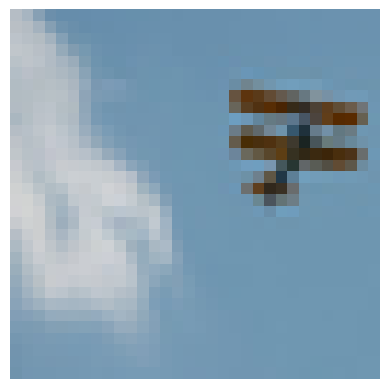

True label: airplane
Prediction: airplane
Confidence: 0.165


In [49]:
saved = torch.load(FINAL_PATH, map_location="cpu", weights_only=True)
inference_model = SmallCNN(num_classes=len(saved["class_names"]))
inference_model.load_state_dict(saved["model_state_dict"], strict=True)
inference_model.eval()
inference_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(tuple(saved["mean"]), tuple(saved["std"])),
])
raw_image, true_label = raw_test[test_ids[0]]
with torch.inference_mode():
    probabilities = inference_model(inference_transform(raw_image).unsqueeze(0)).softmax(dim=1)[0]
confidence, predicted_id = probabilities.max(dim=0)
plt.imshow(raw_image); plt.axis("off"); plt.show()
print("True label:", saved["class_names"][true_label])
print("Prediction:", saved["class_names"][predicted_id.item()])
print("Confidence:", f"{confidence.item():.3f}")

## 19. Project summary and next steps

You completed the workflow: defined a classification problem, validated local data, explored and preprocessed images, augmented training data, established a baseline, trained a CNN and transfer-learning model, compared learning rates, evaluated held-out examples, inspected errors, visualized saliency, measured a quantized model, and saved an inference-ready checkpoint.

**Decisions to document in your report:** selected model and learning rate; validation and test metrics; the transfer-checkpoint overlap caveat; representative errors; quantization size/latency; and limitations of low-resolution CIFAR-10. A sensible next step is to evaluate on fresh images collected from the actual intended setting.